# Task 8: Simple but Effective Visualizations
## Intraday strategy – Fade Support on ES 15min
## Now using real price data from Supabase

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import mplfinance as mpf
from datetime import datetime, timedelta
from supabase import create_client
import os
from dotenv import load_dotenv
import warnings
warnings.filterwarnings('ignore')

load_dotenv()
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")
print("✅ Libraries loaded")

✅ Libraries loaded


In [2]:
# Connect to Supabase (same as before)
supabase = create_client(
    os.getenv("SUPABASE_URL"),
    os.getenv("SUPABASE_SERVICE_ROLE_KEY")
)

def fetch_15min_data(start_date, end_date):
    """Fetch 15min candles from Supabase between two timestamps"""
    start_str = start_date.strftime('%Y-%m-%d %H:%M:%S')
    end_str = end_date.strftime('%Y-%m-%d %H:%M:%S')
    resp = supabase.table('es_15min')\
        .select('*')\
        .gte('timestamp', start_str)\
        .lte('timestamp', end_str)\
        .order('timestamp')\
        .execute()
    df = pd.DataFrame(resp.data)
    if df.empty:
        return df
    df['timestamp'] = pd.to_datetime(df['timestamp']).dt.tz_localize(None)
    df = df.set_index('timestamp')
    df.columns = [c.lower() for c in df.columns]
    return df

In [3]:
# Load trades CSV
trades = pd.read_csv('intraday_backtest_trades_full.csv')
trades['entry_time'] = pd.to_datetime(trades['entry_time'])
trades['exit_time'] = pd.to_datetime(trades['exit_time'])
trades = trades.sort_values('entry_time')
print(f"Loaded {len(trades)} trades")

Loaded 6406 trades


In [4]:
# Calculate cumulative return and drawdown
trades['cum_return'] = trades['pnl_percent'].cumsum()
trades['peak'] = trades['cum_return'].cummax()
trades['drawdown'] = (trades['cum_return'] - trades['peak']) / trades['peak'] * 100

## 1. Equity Curve and Drawdown

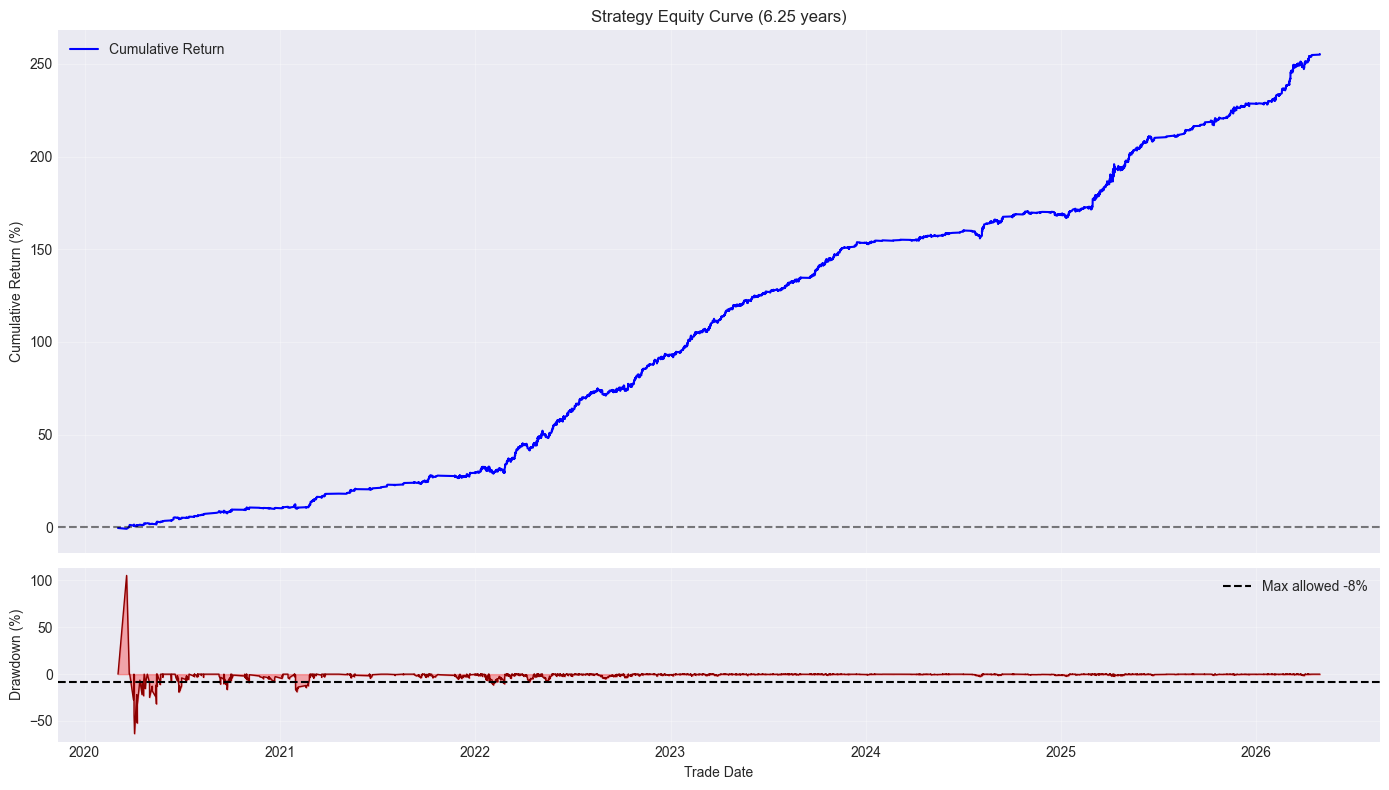

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Equity curve
ax1.plot(trades['entry_time'], trades['cum_return'], color='blue', linewidth=1.5, label='Cumulative Return')
ax1.axhline(0, color='black', linestyle='--', alpha=0.5)
ax1.set_ylabel('Cumulative Return (%)')
ax1.set_title('Strategy Equity Curve (6.25 years)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Drawdown
ax2.fill_between(trades['entry_time'], 0, trades['drawdown'], color='red', alpha=0.3)
ax2.plot(trades['entry_time'], trades['drawdown'], color='darkred', linewidth=1)
ax2.axhline(-8, color='black', linestyle='--', label='Max allowed -8%')
ax2.set_ylabel('Drawdown (%)')
ax2.set_xlabel('Trade Date')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Distribution of Trade Returns

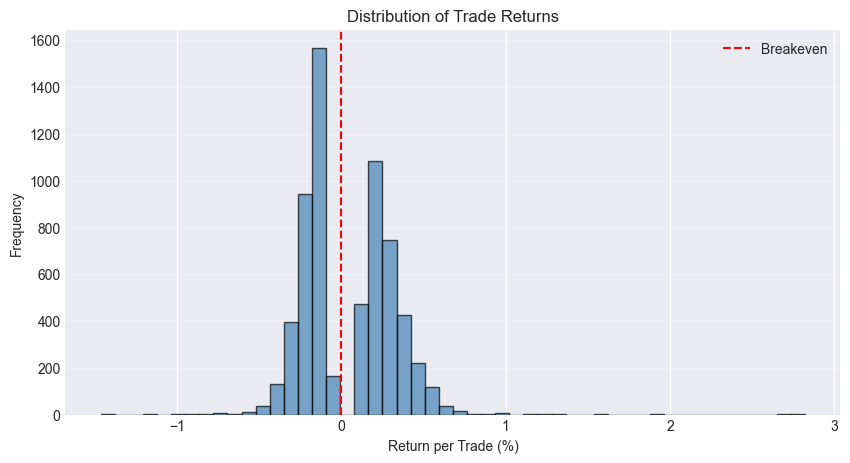

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(trades['pnl_percent'], bins=50, alpha=0.7, color='steelblue', edgecolor='black')
ax.axvline(0, color='red', linestyle='--', label='Breakeven')
ax.set_xlabel('Return per Trade (%)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Trade Returns')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.show()

## 3. Best Trade Example (with real 15min candles)

In [7]:
# Find best trade (highest pnl_points)
best = trades.loc[trades['pnl_points'].idxmax()]
entry_time = best['entry_time']
exit_time = best['exit_time']

# Expand window: 1.5 hours before entry, 1.5 hours after exit
start = entry_time - timedelta(hours=1.5)
end = exit_time + timedelta(hours=1.5)
candles = fetch_15min_data(start, end)

if not candles.empty:
    # Plot with mplfinance
    mpf.plot(candles, type='candle', volume=True, style='charles',
             title=f'Best Trade - {entry_time.date()} (Entry: {best["entry_price"]:.2f}, Exit: {best["exit_price"]:.2f}, PnL: {best["pnl_points"]:.1f} pts)',
             ylabel='Price (ES)',
             hlines=dict(hlines=[best['entry_price'], best['exit_price']], colors=['g','b'], linestyle='--'),
             savefig='best_trade_candles.png')
    print("Chart saved as 'best_trade_candles.png'")
else:
    print("No data found for that period. Check date range.")

Chart saved as 'best_trade_candles.png'


## 4. Worst Trade Example (with real 15min candles)

In [8]:
# Find worst trade (lowest pnl_points)
worst = trades.loc[trades['pnl_points'].idxmin()]
entry_time = worst['entry_time']
exit_time = worst['exit_time']

start = entry_time - timedelta(hours=1.5)
end = exit_time + timedelta(hours=1.5)
candles = fetch_15min_data(start, end)

if not candles.empty:
    mpf.plot(candles, type='candle', volume=True, style='charles',
             title=f'Worst Trade - {entry_time.date()} (Entry: {worst["entry_price"]:.2f}, Exit: {worst["exit_price"]:.2f}, PnL: {worst["pnl_points"]:.1f} pts)',
             ylabel='Price (ES)',
             hlines=dict(hlines=[worst['entry_price'], worst['exit_price']], colors=['g','r'], linestyle='--'),
             savefig='worst_trade_candles.png')
    print("Chart saved as 'worst_trade_candles.png'")
else:
    print("No data found for that period.")

Chart saved as 'worst_trade_candles.png'


## 5. Monthly Heatmap of Returns (from trades)

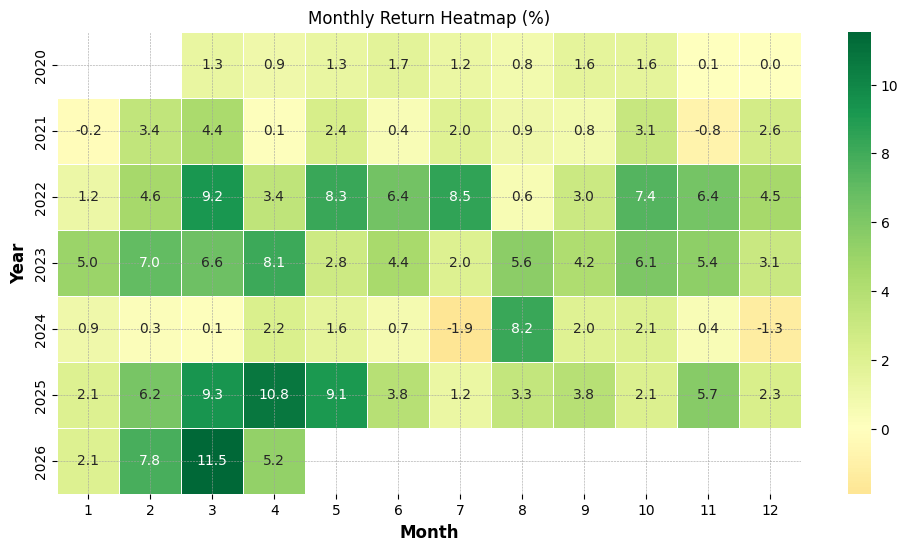

In [9]:
trades['year'] = trades['entry_time'].dt.year
trades['month'] = trades['entry_time'].dt.month
monthly_pnl = trades.groupby(['year', 'month'])['pnl_percent'].sum().unstack()
plt.figure(figsize=(12, 6))
sns.heatmap(monthly_pnl, annot=True, fmt='.1f', cmap='RdYlGn', center=0, linewidths=0.5)
plt.title('Monthly Return Heatmap (%)')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

## 6. Win Rate by Month of Year

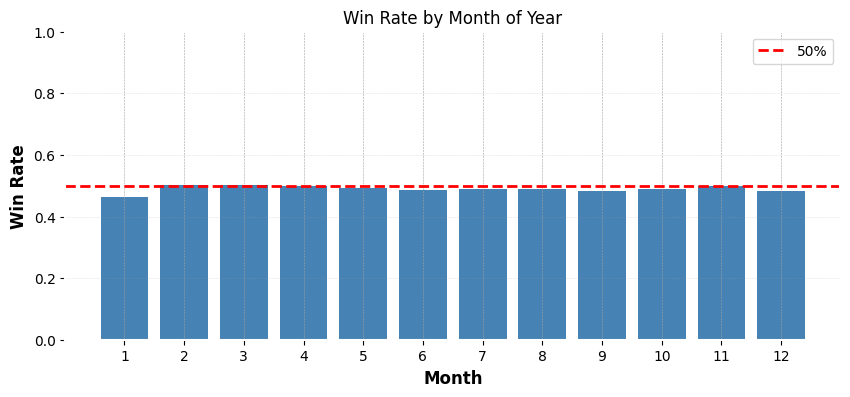

In [10]:
monthly_winrate = trades.groupby('month')['outcome'].apply(lambda x: (x == 'win').mean())
plt.figure(figsize=(10, 4))
plt.bar(monthly_winrate.index, monthly_winrate.values, color='steelblue')
plt.axhline(0.5, color='red', linestyle='--', label='50%')
plt.title('Win Rate by Month of Year')
plt.xlabel('Month')
plt.ylabel('Win Rate')
plt.ylim(0, 1)
plt.xticks(range(1,13))
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

## 7. Equity Curve by Year (Faceted)

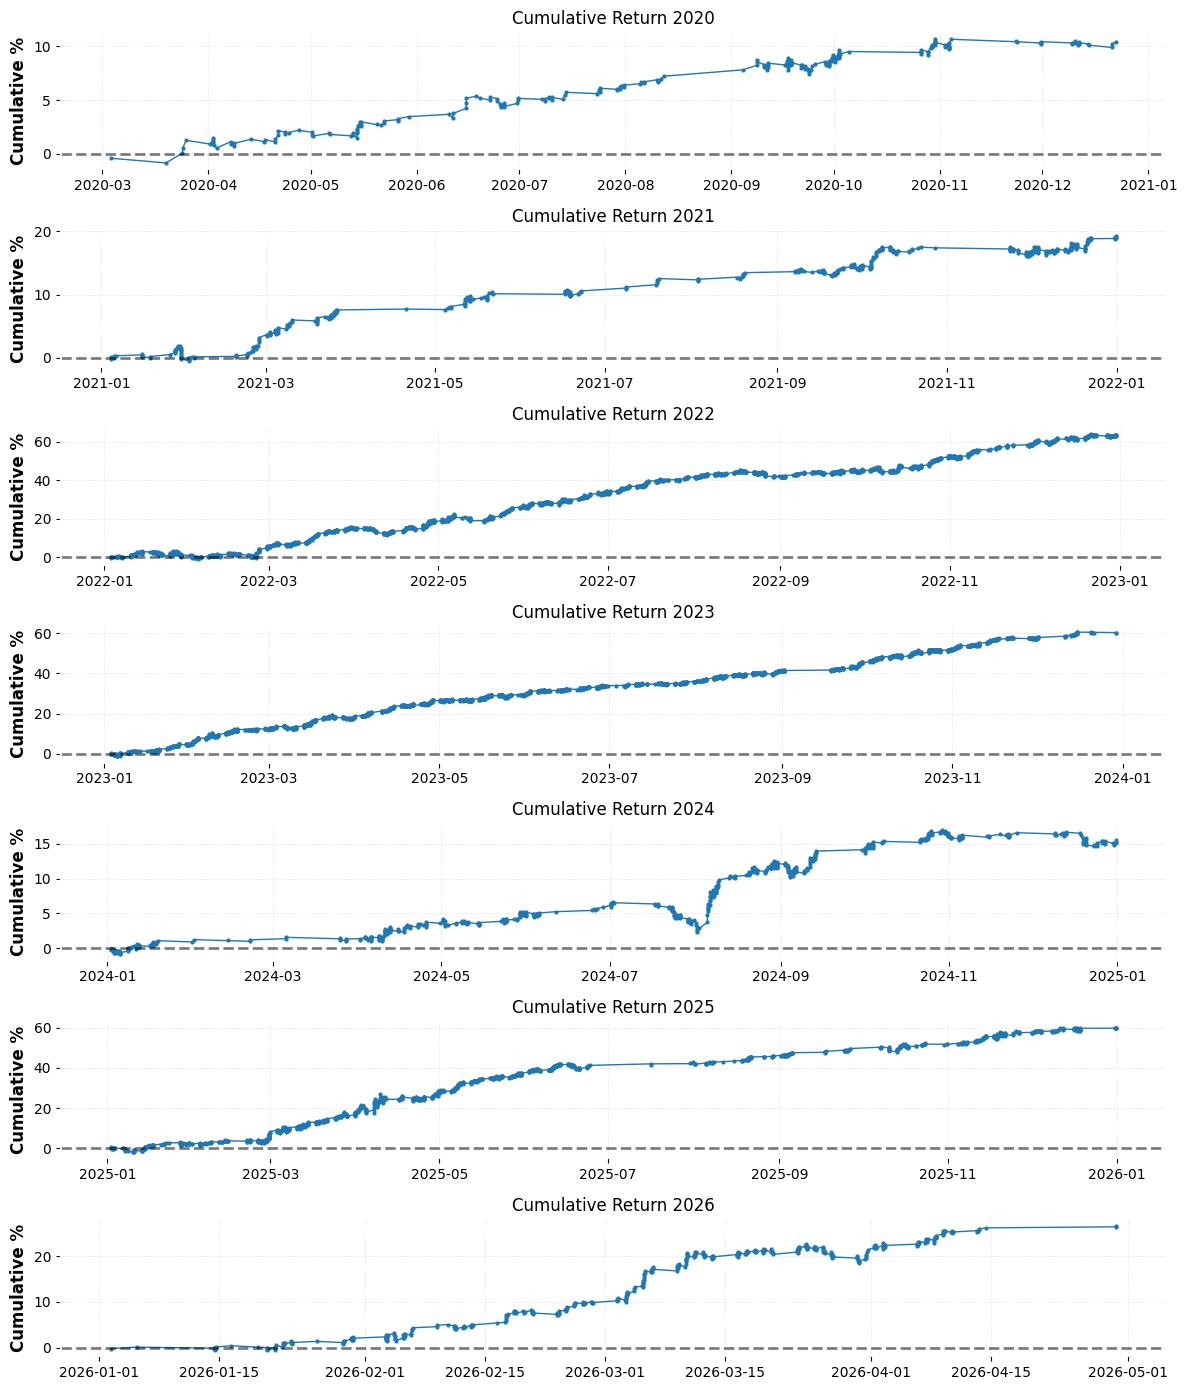

In [11]:
years = trades['year'].unique()
fig, axes = plt.subplots(len(years), 1, figsize=(12, 2*len(years)), sharex=False)
for i, year in enumerate(sorted(years)):
    year_trades = trades[trades['year'] == year].copy()
    year_trades['cum_yr'] = year_trades['pnl_percent'].cumsum()
    ax = axes[i]
    ax.plot(year_trades['entry_time'], year_trades['cum_yr'], marker='o', markersize=2, linewidth=1)
    ax.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax.set_title(f'Cumulative Return {year}')
    ax.set_ylabel('Cumulative %')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()